# Hierarchies with tolerances: the Pareto front and pass statistics
[![hierarchy_tolerances_pareto.ipynb](https://img.shields.io/badge/github-%23121011.svg?logo=github)](https://github.com/ampl/colab.ampl.com/blob/master/authors/glebbelov/solver-features/hierarchy_tolerances_pareto.ipynb) [![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ampl/colab.ampl.com/blob/master/authors/glebbelov/solver-features/hierarchy_tolerances_pareto.ipynb) [![Open In Deepnote](https://deepnote.com/buttons/launch-in-deepnote-small.svg)](https://deepnote.com/launch?url=https://github.com/ampl/colab.ampl.com/blob/master/authors/glebbelov/solver-features/hierarchy_tolerances_pareto.ipynb) [![Open In Kaggle](https://kaggle.com/static/images/open-in-kaggle.svg)](https://kaggle.com/kernels/welcome?src=https://github.com/ampl/colab.ampl.com/blob/master/authors/glebbelov/solver-features/hierarchy_tolerances_pareto.ipynb) [![Open In Gradient](https://assets.paperspace.io/img/gradient-badge.svg)](https://console.paperspace.com/github/ampl/colab.ampl.com/blob/master/authors/glebbelov/solver-features/hierarchy_tolerances_pareto.ipynb) [![Open In SageMaker Studio Lab](https://studiolab.sagemaker.aws/studiolab.svg)](https://studiolab.sagemaker.aws/import/github/ampl/colab.ampl.com/blob/master/authors/glebbelov/solver-features/hierarchy_tolerances_pareto.ipynb) [![Powered by AMPL](https://h.ampl.com/https://github.com/ampl/colab.ampl.com/blob/master/authors/glebbelov/solver-features/hierarchy_tolerances_pareto.ipynb)](https://ampl.com)

Description: Cost, emissions and starts in a unit commitment model: objective priorities and tolerances as AMPL suffixes, per-pass statistics, native against emulated hierarchies, and the Pareto front traced by a tolerance sweep

Tags: mp, multi-objective, pareto-front, suffixes, unit-commitment, energy, milp, amplpy, highs, gurobi

<!--
Domain: Energy
Subdomain: Unit Commitment
Model type: MILP
Level: Lecture
Algorithm: Lexicographic Optimization
Subject: Multi-Objective Optimization
-->

Notebook author: Gleb Belov <<gleb@ampl.com>>

References:
1. MP solver features, multiple objectives: https://mp.ampl.com/features-guide.html
2. Haimes, Y.Y., Lasdon, L.S., Wismer, D.A. (1971). On a bicriterion formulation of the problems of integrated system identification and system optimization. *IEEE Transactions on Systems, Man, and Cybernetics* 1(3), 296-297.
3. Mavrotas, G. (2009). Effective implementation of the epsilon-constraint method in multi-objective mathematical programming problems. *Applied Mathematics and Computation* 213(2), 455-465.
4. Ehrgott, M. (2005). *Multicriteria Optimization*. Springer.

In [1]:
# Install dependencies
%pip install -q amplpy pandas matplotlib

In [2]:
# Google Colab & Kaggle integration
from amplpy import AMPL, ampl_notebook

ampl = ampl_notebook(
    modules=["highs", "gurobi"],  # modules to install
    license_uuid="default",  # license to use
)  # instantiate AMPL object and register magics

## The point

A unit commitment plan has more than one goal: **cost**, **emissions**, and the number of **starts** (wear on the
units). With AMPL and the MP solver drivers you state them as objectives and let the solver take them in order:
a **hierarchy** with priorities, where a **tolerance** says how much a higher goal may give up for a lower one.
This notebook shows:

* how to set priorities and tolerances (IN suffixes) and read **per-pass statistics** (OUT suffixes) in amplpy;
* that a tolerance is a **permission, not a target**, and how native and emulated hierarchies read it;
* how a sweep of the tolerance traces the **Pareto front**, the cost of each tonne of emissions avoided.

In [3]:
SOLVER = "highs"  # emulated hierarchy (obj:multi=2) works on any MP solver
SOLVER_NATIVE = "gurobi"  # a solver with a native hierarchy (obj:multi=1): gurobi, xpress, cplex, copt

## The model and its three objectives

The unit commitment model of this series (on/off, output, starts, demand, reserve, inertia; the cost as a defined
variable `Cost`), with two more objectives: emissions, and the number of starts. The three suffix declarations are
model text: the multi-objective **IN suffixes**.

In [4]:
MODEL = (
    r"""
set UNITS;
param T integer > 0;
set HOURS := 1..T;
param dt > 0;                          # hours per period
param demand {HOURS} >= 0;             # MW
param reserve {HOURS} >= 0;            # spinning reserve required, MW
param min_online integer >= 0;         # units online, for system inertia
param pmin {UNITS} >= 0;
param pmax {g in UNITS} >= pmin[g];
param ramp {UNITS} > 0;                # MW per period
param minup {UNITS} integer >= 1;
param mindn {UNITS} integer >= 1;
param fuel {UNITS} >= 0;               # $/MWh
param noload {UNITS} >= 0;             # $/h while on
param startcost {UNITS} >= 0;          # $ per start
param emis {UNITS} >= 0;               # t CO2 per MWh
param on0 {UNITS} binary;              # on before the horizon
param p0 {UNITS} >= 0;                 # output before the horizon

var On {UNITS, HOURS} binary;
var Start {UNITS, HOURS} >= 0, <= 1;
var Stop {UNITS, HOURS} >= 0, <= 1;
var P {g in UNITS, HOURS} >= 0, <= pmax[g];

var Cost = sum {g in UNITS, t in HOURS}
             (dt * (fuel[g] * P[g,t] + noload[g] * On[g,t]) + startcost[g] * Start[g,t]);
minimize Total_Cost: Cost;

subject to Output_Lo {g in UNITS, t in HOURS}: P[g,t] >= pmin[g] * On[g,t];
subject to Output_Up {g in UNITS, t in HOURS}: P[g,t] <= pmax[g] * On[g,t];
subject to Balance {t in HOURS}: sum {g in UNITS} P[g,t] = demand[t];
subject to Spinning_Reserve {t in HOURS}:
   sum {g in UNITS} (pmax[g] * On[g,t] - P[g,t]) >= reserve[t];
subject to Inertia {t in HOURS}: sum {g in UNITS} On[g,t] >= min_online;
subject to Switch {g in UNITS, t in HOURS}:
   Start[g,t] - Stop[g,t] = On[g,t] - (if t = 1 then on0[g] else On[g,t-1]);
subject to Ramp_Up {g in UNITS, t in HOURS}:
   P[g,t] - (if t = 1 then p0[g] else P[g,t-1]) <= ramp[g] + pmax[g] * Start[g,t];
subject to Ramp_Down {g in UNITS, t in HOURS}:
   (if t = 1 then p0[g] else P[g,t-1]) - P[g,t] <= ramp[g] + pmax[g] * Stop[g,t];
subject to Min_Up {g in UNITS, t in HOURS}:
   sum {s in max(1, t - minup[g] + 1) .. t} Start[g,s] <= On[g,t];
subject to Min_Down {g in UNITS, t in HOURS}:
   sum {s in max(1, t - mindn[g] + 1) .. t} Stop[g,s] <= 1 - On[g,t];
"""
    + r"""
minimize Emissions: sum {g in UNITS, t in HOURS} dt * emis[g] * P[g,t];
minimize Starts: sum {g in UNITS, t in HOURS} Start[g,t];
suffix objpriority IN, integer;
suffix objreltol IN;
suffix objabstol IN;
"""
)

In [5]:
import pandas as pd

# A small thermal fleet: seven units of four types, twelve 2-hour periods
units = pd.DataFrame(
    {
        "pmin": [300, 120, 80, 20, 300, 120, 80],  # MW
        "pmax": [500, 350, 250, 100, 500, 350, 250],  # MW
        "ramp": [60, 80, 120, 100, 60, 80, 120],  # MW per period
        "minup": [12, 6, 2, 1, 12, 6, 2],  # periods
        "mindn": [12, 5, 2, 1, 12, 5, 2],  # periods
        "fuel": [9, 24, 38, 75, 9, 25, 39],  # $/MWh
        "noload": [800, 500, 300, 100, 800, 500, 300],  # $/h while on
        "startcost": [9000, 6000, 2000, 400, 9000, 6000, 2000],  # $ per start
        "emis": [0, 0.95, 0.37, 0.55, 0, 0.969, 0.3774],  # t CO2 per MWh
        "on0": [1, 1, 0, 0, 1, 1, 0],  # on before the horizon
        "p0": [400, 200, 0, 0, 400, 200, 0],  # MW before the horizon
    },
    index=["NUKE1", "COAL1", "CCGT1", "GT1", "NUKE2", "COAL2", "CCGT2"],
)
demand = [1027, 960, 1093, 1325, 1557, 1490, 1027, 960, 1557, 1656, 1457, 1093]  # MW


def load(units, reserve_frac, demand=demand, model=MODEL):
    """Reset the AMPL session, read the model and feed the data."""
    ampl.reset()
    ampl.eval(model)
    ampl.set_data(units, "UNITS")
    ampl.param["T"] = len(demand)
    ampl.param["dt"] = 2
    ampl.param["min_online"] = 2
    ampl.param["demand"] = {t + 1: d for t, d in enumerate(demand)}
    ampl.param["reserve"] = {
        t + 1: round(reserve_frac * d) for t, d in enumerate(demand)
    }


units

,pmin,pmax,ramp,minup,mindn,fuel,noload,startcost,emis,on0,p0
NUKE1,300,500,60,12,12,9,800,9000,0.0000,1,400
COAL1,120,350,80,6,5,24,500,6000,0.9500,1,200
CCGT1,80,250,120,2,2,38,300,2000,0.3700,0,0
GT1,20,100,100,1,1,75,100,400,0.5500,0,0
NUKE2,300,500,60,12,12,9,800,9000,0.0000,1,400
COAL2,120,350,80,6,5,25,500,6000,0.9690,1,200
CCGT2,80,250,120,2,2,39,300,2000,0.3774,0,0


## Each goal alone

First the two ends: cheapest plan, cleanest plan. With several objectives declared and no `obj:multi`, the solver
uses the current objective, chosen with AMPL's `objective` command:

In [6]:
ends = {}
for name in ("Total_Cost", "Emissions"):
    load(units, reserve_frac=0.08)
    ampl.eval(f"objective {name};")
    ampl.solve(solver=SOLVER, verbose=False)
    ends[name] = {
        o: round(ampl.get_value(o), 1) for o in ("Cost", "Emissions", "Starts")
    }
pd.DataFrame(ends).T

,Cost,Emissions,Starts
Total_Cost,483106.0,6450.7,4.0
Emissions,531204.0,4184.3,6.0


Cleanest costs about 10 % more than cheapest and emits about 35 % less. Between the two lies a range of
compromises.

## Suffixes for multiple objectives

| suffix | kind | meaning |
|---|---|---|
| `.objpriority` | IN | higher priority is optimised first |
| `.objreltol`, `.objabstol` | IN | how much this objective may degrade (relative, absolute) for lower priorities |
| `.objweight` | IN | weight when objectives of the same priority are blended |
| `.objpass_objval`, `.objpass_runtime`, `.objpass_mipgap`, ... | OUT | per-pass statistics, with `obj:multi:stats=1` |

`obj:multi=1` uses the solver's native hierarchy where it has one; `obj:multi=2` makes MP **emulate** it pass by
pass on any solver.

In [7]:
def hierarchy(
    solver, multi, objectives=("Total_Cost", "Emissions", "Starts"), reltol=None
):
    # priorities in the given order, tolerances from reltol; returns values and pass statistics
    load(units, reserve_frac=0.08)
    for o in ("Total_Cost", "Emissions", "Starts"):
        if o not in objectives:
            ampl.eval(f"drop {o};")
    for prio, o in zip(range(len(objectives), 0, -1), objectives):
        obj = ampl.get_objective(o)
        obj.set_suffix("objpriority", prio)  # IN suffix
        tol = (reltol or {}).get(o)
        if tol is not None:
            obj.set_suffix("objreltol", tol or 1e-20)  # 0 would mean "not set"
    ampl.solve(
        solver=solver,
        **{f"{solver}_options": f"obj:multi={multi} obj:multi:stats=1"},
        verbose=False,
    )
    values = {o: round(ampl.get_value(o), 2) for o in ("Cost", "Emissions", "Starts")}
    stats = {}
    for o in objectives:  # OUT suffixes, one value per objective
        try:
            v = ampl.get_objective(o).get_values(["objpass_objval", "objpass_runtime"])
            stats[o] = dict(zip(("pass optimum", "pass seconds"), v.to_list()[0]))
        except Exception:
            stats[o] = "no per-pass statistics"
    return ampl.solve_result, values, stats


tol = {"Total_Cost": 0.02, "Emissions": 0.05}
result, values, stats = hierarchy(SOLVER, 2, reltol=tol)
print(result, values)
pd.DataFrame(stats).T

solved {'Cost': 492768.12, 'Emissions': 6166.36, 'Starts': 4}


,pass optimum,pass seconds
Total_Cost,483106.000000,0.510832
Emissions,5872.722743,1.350218
Starts,4.000000,1.137264


Read the passes: cost first, at its optimum; then emissions, with cost allowed 2 % above that optimum; then starts,
with emissions allowed 5 % above *their* pass optimum.

## A tolerance is a permission, not a target

Compare the emissions in the final plan with the emissions pass optimum above. The last pass minimises starts and
may use the whole 5 % allowance on emissions, **even when starts do not improve**: any plan within the tolerance is
as good as any other for that pass. Drop the third objective and emissions stay at their pass optimum:

In [8]:
_, two, _ = hierarchy(SOLVER, 2, objectives=("Total_Cost", "Emissions"), reltol=tol)
print("cost, emissions (no starts pass):", two)
print("cost, emissions (5 %), starts:   ", values)
print(
    "emissions ratio",
    round(values["Emissions"] / two["Emissions"], 4),
    " starts",
    two["Starts"],
    "->",
    values["Starts"],
)

cost, emissions (no starts pass): {'Cost': 492768.12, 'Emissions': 5872.72, 'Starts': 4}
cost, emissions (5 %), starts:    {'Cost': 492768.12, 'Emissions': 6166.36, 'Starts': 4}
emissions ratio 1.05  starts 4 -> 4


If emissions should stay at their best, give them a tolerance of 0 (or a small absolute one, `.objabstol`); give a
tolerance only to the goals you are ready to trade.

## Native and emulated hierarchies read a tolerance differently

The emulator holds cost to exactly 1.02 times its pass optimum. A native hierarchy applies the tolerance to its own
pass bound, so the numbers can differ slightly, in either goal:

In [9]:
rows = {}
for solver, multi in ((SOLVER, 2), (SOLVER_NATIVE, 1)):
    result, v, s = hierarchy(solver, multi, reltol=tol)
    rows[f"{solver}, obj:multi={multi}"] = v
cap = 1.02 * ends["Total_Cost"]["Cost"]
table = pd.DataFrame(rows).T
table["cost vs 2 % cap"] = (table["Cost"] - cap).round(2)
table

,Cost,Emissions,Starts,cost vs 2 % cap
"highs, obj:multi=2",492768.12,6166.36,4.0,0.00
"gurobi, obj:multi=1",492817.40,5870.68,4.0,49.28


Same suffixes, two readings: check which one your solver applies before you quote "within 2 %". (Some native modes
also report no per-pass statistics; the emulated mode always does.)

## The Pareto front: sweep the tolerance

With two objectives, cost first and emissions second, each value of the cost tolerance gives one point: the
cleanest plan that costs at most that much more than the cheapest. This is the **epsilon-constraint** method, with
the bound written as a tolerance suffix. Every point is **weakly efficient**: no plan is better in both goals.

In [10]:
curve = []
for t in (0, 0.005, 0.01, 0.02, 0.03, 0.05, 0.08, 0.10):
    _, v, _ = hierarchy(
        SOLVER, 2, objectives=("Total_Cost", "Emissions"), reltol={"Total_Cost": t}
    )
    curve.append(dict(tolerance=t, cost=v["Cost"], emissions=v["Emissions"]))
front = pd.DataFrame(curve)
front["$ per tonne avoided"] = (-front.cost.diff() / front.emissions.diff()).round(1)
front

,tolerance,cost,emissions,$ per tonne avoided
0,0.000,483106.00,6450.69,NaN
1,0.005,485521.53,6206.23,9.9
2,0.010,487937.06,6091.96,21.1
3,0.020,492768.12,5872.72,22.0
4,0.030,497599.18,5309.47,8.6
5,0.050,507261.30,4893.80,23.2
6,0.080,521754.48,4308.76,24.8
7,0.100,531204.00,4184.30,75.9


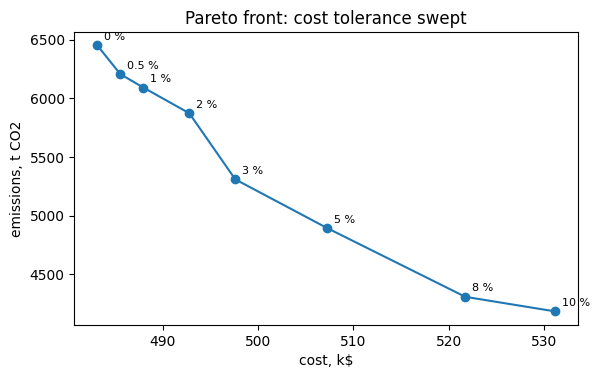

In [11]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.plot(front.cost / 1000, front.emissions, "o-")
for _, r in front.iterrows():
    ax.annotate(
        f"{100 * r.tolerance:g} %",
        (r.cost / 1000, r.emissions),
        textcoords="offset points",
        xytext=(5, 4),
        fontsize=8,
    )
ax.set_xlabel("cost, k$")
ax.set_ylabel("emissions, t CO2")
ax.set_title("Pareto front: cost tolerance swept")
plt.show()

The slope between two points is the price of a tonne at that tolerance. A MIP's front need not be convex: the
price jumps between commitments (here from about 10 to 22 $/t, back to 9, then up to 76 $/t for the last tonnes,
when the cleanest units must run). So sweep more points where the price changes, and quote the price of a step, not
a single "cost of carbon" for the whole curve.

## Takeaways

* Priorities and tolerances are **IN suffixes** on objectives (`.objpriority`, `.objreltol`, `.objabstol`); per-pass
  results are **OUT suffixes** (`.objpass_objval`, `.objpass_runtime`, ...) with `obj:multi:stats=1`.
* `obj:multi=2` emulates a hierarchy on any MP solver; `obj:multi=1` uses a native one where available.
* A tolerance is a permission: a lower pass may use all of it even without gain. Give tolerances only to goals you
  are ready to trade.
* Native and emulated modes apply a relative tolerance to different bounds; the difference is small but real.
* A sweep of the first objective's tolerance traces the Pareto front, and its slopes are the prices of the trade.